# Batch_03 data samples — context and schemas

Read this before analyzing the data. It describes what the two sample
sources are, what each table contains, how they relate, and — just as
important — what is **not** in this data.

Sources on disk: `docs/batch_03/data-samples/` (see its README for the
anonymization details). Loaders: `eda/src/eda_tools/ndjson.py`.

## The two sources

1. **Joined firehose stream** (`firehose-full-{1,2,3}.ndjson`, 933
   events) — the upstream DSP's joined streaming log. Each line is one
   event combining a bid **request** (the auction context and the
   candidate ads), the delivered **impression**, and usually an
   **activity** array of post-impression video events. Anonymized by
   the client before sharing: user/device identifiers, precise geo,
   consent strings, URLs, and content titles replaced; business data
   (advertiser/campaign/line-item/creative/deal IDs, prices, targeting,
   publisher/app data) intact.
2. **Delivery-control export** (`sigma_sample_file.ndjson`, 130
   records) — a selected export from the client's Postgres: the
   campaign-management hierarchy (12 organizations, 12 ad accounts,
   14 campaigns, 14 ad sets, 78 ads), chosen so its DSP IDs match the
   delivered impressions in the firehose files.

### What each file contains

```mermaid
flowchart LR
  subgraph FH["firehose-full-1/2/3.ndjson — one EVENT per line (933 total)"]
    EV["event"]
    EV --> RQ["request<br/>auctionid, inventory_source"]
    RQ --> BR["bidrequest (OpenRTB ext)<br/>app / device.geo / imp[].video / user"]
    RQ --> AC["adcandidates[] — 1 to 15<br/>line_item_id, campaign_id, deal_id,<br/>bidding.*, pacing.*"]
    EV --> IM["impression — the win<br/>adgroupid.accountid/campaignid/lineitemid,<br/>bid & win price micros, requestid_str"]
    EV --> AV["activity[] — 0 to n<br/>START / Q1 / MID / Q3"]
  end

  subgraph DC["sigma_sample_file.ndjson — one ENTITY per line (130)"]
    EN["entity record<br/>entity_type picks the shape:<br/>organization (12) / ad_account (12) /<br/>campaign (14) / adset (14) / ad (78)"]
  end
```

### How the loaders map files to DataFrames

Three loaders read the **same** firehose files, each flattening to a
different grain; the fourth reads the entity file.

```mermaid
flowchart LR
  F1["firehose-full-*.ndjson"] --> LF["load_firehose()"]
  F1 --> LC["load_candidates()"]
  F1 --> LA["load_activity()"]
  F2["sigma_sample_file.ndjson"] --> LD["load_delivery_control()"]

  LF --> DF1["events — 1 row per EVENT (933)<br/>request + impression flattened,<br/>lists dropped, candidate/activity counts added"]
  LC --> DF2["candidates — 1 row per CANDIDATE (4,569)<br/>adcandidates[] exploded,<br/>+ request context columns"]
  LA --> DF3["activity — 1 row per VIDEO EVENT (2,660)<br/>activity[] exploded"]
  LD --> DF4["entities — 1 row per ENTITY (130)<br/>split with entity_type"]

  DF1 -. "join on auction_key" .- DF2
  DF1 -. "join on auction_key / requestid_str" .- DF3
```


## What is and isn't in this data

**Impressions are wins-only, by construction.** Every firehose event
carries exactly one `impression` — the creative that was *delivered*,
with `bid_price_micros_usd`, `win_price_micros_usd`, and bid-shading
info. The joined stream is assembled around delivered impressions, so
lost bids are not in this sample. The production equivalent of this
side is the win-log stream.

**Candidates are in `request.adcandidates[]`.** These are the line
items *eligible* for the auction (1–15 per request here, mean 4.9) with
their bidding and pacing settings. Their IDs must **not** be read as
delivered — exactly one of them won, and it matches
`impression.adgroupid.lineitemid` (verified below for all 933 events).

**Attributions are NOT in these samples.** Conversions and attribution
live in the client warehouse (`gold_kochava_*_day_attribution` for web,
the app-event tables for in-app) and are pending data access. This data
covers only the request → candidate → impression side of the future
label join; **no training label can be built from this sample alone**.

**Activity** is the post-impression video telemetry (START, Q1, MID,
Q3), present on 860 of the 933 impressions.

## How the tables relate

The grain is the **won impression**: one firehose event per delivered
impression, carrying its auction's bid request, the eligible candidates,
and the playback activity. Solid lines are joins within the sample;
dashed lines are the DSP-integer bridge to the delivery-control export
and the out-of-sample label join.

```mermaid
erDiagram
    BID_REQUEST ||--|{ CANDIDATE : "adcandidates (1-15 eligible)"
    BID_REQUEST ||--|| WON_IMPRESSION : "one per event (auction_key)"
    WON_IMPRESSION ||..|| CANDIDATE : "winner (line_item_id match)"
    WON_IMPRESSION ||--o{ ACTIVITY : "video playback events"

    ORGANIZATION ||--o{ AD_ACCOUNT : "ua_organization_id"
    AD_ACCOUNT ||--o{ CAMPAIGN : "ua_ad_account_id"
    CAMPAIGN ||--o{ ADSET : "ua_campaign_id"
    ADSET ||--o{ AD : "ua_adset_id"

    ADSET ||..o{ CANDIDATE : "appears as candidate across auctions (beeswax_line_item_id = line_item_id, 1 ad set per candidate row)"
    ADSET ||..o{ WON_IMPRESSION : "its wins across auctions (beeswax_line_item_id = lineitemid)"
    AD_ACCOUNT ||..o{ WON_IMPRESSION : "beeswax_advertiser_id = advertiser_id"

    WON_IMPRESSION ||..o{ ATTRIBUTED_CONVERSION : "label join - NOT in batch_03"

    BID_REQUEST {
        string auction_key PK
        string app_bundle
        string device_type
        string geo_country
        float imp0_bidfloor
        list imp_video_specs
    }
    CANDIDATE {
        string auction_key FK
        string line_item_id "DSP integer id"
        string campaign_id
        string account_id
        string deal_id
        int bidding_bid_price_micros
        bool pacing_pace_delivery
    }
    WON_IMPRESSION {
        string auction_key FK
        string requestid_str
        string adgroupid_lineitemid "the winner"
        string advertiser_id
        string creative_id
        int bid_price_micros_usd
        int win_price_micros_usd
        int rx_timestamp_usecs
    }
    ACTIVITY {
        string auction_key FK
        string requestid_str FK
        string type "START / Q1 / MID / Q3"
        int rx_timestamp_usecs
    }
    AD_ACCOUNT {
        string ua_ad_account_id PK
        string beeswax_advertiser_id "DSP bridge"
    }
    ADSET {
        string ua_adset_id PK
        string ua_campaign_id FK
        string beeswax_line_item_id "DSP bridge"
        float bid
        string bidding_strategy "null placeholder"
        string status "per-entity, not resolved"
    }
    ATTRIBUTED_CONVERSION {
        string source "gold_kochava / app-event tables"
        string windows "7 / 14 / 30 day"
        string availability "pending data access"
    }
```

Rendering note: the diagram renders natively in JupyterLab >= 4.1 (this
suite ships 4.6). Cardinalities: every event has exactly one won
impression; exactly one candidate is the winner; activity is 0-to-many
(860/933 impressions have events); the delivery-control export covers a
matched subset of the line items seen (14 of 121). A candidate row
references exactly one ad set; the many-side on CANDIDATE and
WON_IMPRESSION reflects the same ad set recurring across auctions,
not one candidate spanning several ad sets.

In [1]:
import pandas as pd

from eda_tools import (
    load_activity,
    load_candidates,
    load_delivery_control,
    load_firehose,
)

pd.set_option("display.max_columns", 200)

events = load_firehose()
candidates = load_candidates()
activity = load_activity()
entities = load_delivery_control()

print("events    ", events.shape)
print("candidates", candidates.shape)
print("activity  ", activity.shape)
print("entities  ", entities.shape)

events     (933, 172)
candidates (4569, 19)
activity   (2660, 20)
entities   (130, 84)


## 1. Firehose events — `load_firehose()`

One row per joined event. Column groups:

- `request.bidrequest.*` — the OpenRTB-extension bid request: `app.*`
  (bundle, name, publisher), `device.*` (type, os, geo, anonymized ids),
  `imp[]` (kept as a list column: ad slot, `bidfloor`, `video` specs),
  `user.*` (anonymized), `cur`, `tmax`.
- `request.auctionid.*` / `impression.auctionid.*` — the auction id
  struct `{hostid, tid, timestamp}`; the loader derives the scalar
  **`auction_key`** from it on every frame.
- `impression.*` — the delivered creative: `adgroupid.{accountid,
  campaignid,lineitemid}`, `advertiser_id`, `creative_id`,
  `bid_price_micros_usd`, `win_price_micros_usd` (micro-USD),
  `bid_shading_info.*`, `rx_timestamp_usecs`, `requestid_str`.
- Loader-added: `source_file`, `candidate_count`, `activity_count`
  (the raw `adcandidates`/`activity` lists are dropped here — use the
  dedicated loaders).

In [2]:
prefixes = events.columns.str.extract(r"^([^.]+(?:\.[^.]+)?)", expand=False)
summary = (
    events.notna().mean().groupby(prefixes).agg(["size", "mean"])
    .rename(columns={"size": "n_cols", "mean": "avg_nonnull_share"})
    .sort_values("n_cols", ascending=False)
)
summary.head(25)

,n_cols,avg_nonnull_share
request.bidrequest,135,0.661601
impression.adgroupid,4,1.000000
impression.bid_shading_info,4,0.770900
impression.auctionid,3,1.000000
request.auctionid,3,1.000000
impression.win_price,3,1.000000
activity_count,1,1.000000
impression.requestid_str,1,1.000000
request.inventory_source,1,1.000000
request.agent_data,1,0.157556


## 2. Candidates — `load_candidates()`

One row per eligible candidate, exploded from `request.adcandidates[]`:
`line_item_id`, `campaign_id`, `account_id`, `deal_id`, `creative_ids`
(list), `targeted_segments` (list), `bidding.bid_price_micros`,
`bidding.bid_modifier_multipliers_product`, `pacing.pace_delivery` —
plus join keys (`auction_key`, `source_file`) and request context
(`app.*`, `device.*`, `geo.country`, `imp0.bidfloor`). All entity IDs
are the DSP's integer IDs as strings.

In [3]:
candidates.dtypes.to_frame("dtype").join(candidates.notna().mean().rename("nonnull_share").round(2))

,dtype,nonnull_share
auction_key,str,1.00
source_file,str,1.00
inventory_source,str,1.00
app.bundle,str,0.95
app.name,str,0.93
device.devicetype,str,1.00
device.os,str,1.00
geo.country,str,1.00
imp0.bidfloor,float64,0.27
line_item_id,str,1.00


## 3. Activity — `load_activity()`

One row per post-impression video event. `type` ∈ START/Q1/MID/Q3 (+
others if present); carries the same `adgroupid`/`advertiser_id`/
`creative_id` ids as the impression, `rx_timestamp_usecs`, and joins
back via `auction_key` or `requestid_str`.

In [4]:
print(activity["type"].value_counts(), end="\n\n")
activity.dtypes.to_frame("dtype").head(20)

type
START       848
Q1          688
MID         528
Q3          376
COMPLETE    211
PAUSE         7
RESUME        1
MUTE          1
Name: count, dtype: int64



,dtype
inventory_source,str
type,str
user_id,str
user_data,str
rx_timestamp_usecs,str
creative_id,str
advertiser_id,str
auctionid_str,str
is_gdpr,bool
requestid_str,str


## 4. Delivery control — `load_delivery_control()`

One row per entity; split on `entity_type`. Hierarchy and per-type key
fields (columns are sparse — each type fills its own):

| entity_type | parent link | notable fields |
|---|---|---|
| `organization` | — | `status`, `timezone`, `currency`, spend limits |
| `ad_account` | `ua_organization_id` | **`beeswax_advertiser_id`** |
| `campaign` | `ua_ad_account_id` | **`beeswax_campaign_id`**, `objective_type`, budgets, flight dates, frequency cap |
| `adset` | `ua_campaign_id` | **`beeswax_line_item_id`**, `bid`, `bidding.*` (raw config), `targeting`, budgets |
| `ad` | `ua_adset_id` | **`beeswax_ad_id`**, `beeswax_creative_id`, `ua_creative_id` |

Caveats (from the sample README + checks below):

- `bidding_strategy` and `pacing` are **null placeholders** in this
  export — the two new ad-set fields are not populated.
- `status` is resolved **per entity**: a child's status does not
  incorporate its parent's.
- This is a **matched subset**, not a catalog: its 14 ad sets cover 14
  of the 121 distinct line items seen in the firehose impressions.
- Export reflects Postgres state at query time, which can differ from
  the state when an impression occurred.

In [5]:
for etype in ["organization", "ad_account", "campaign", "adset", "ad"]:
    sub = entities[entities["entity_type"] == etype]
    cols = sub.dropna(axis=1, how="all").columns.tolist()
    print(f"{etype} ({len(sub)} rows, {len(cols)} non-null cols):")
    print("  ", cols, "\n")

organization (12 rows, 9 non-null cols):
   ['name', 'entity_name', 'entity_id', 'currency', 'entity_type', 'spend_limit_unlimited', 'status', 'timezone', 'ua_organization_id'] 

ad_account (12 rows, 10 non-null cols):
   ['name', 'entity_name', 'entity_id', 'currency', 'entity_type', 'status', 'timezone', 'ua_organization_id', 'beeswax_advertiser_id', 'ua_ad_account_id'] 

campaign (14 rows, 22 non-null cols):
   ['name', 'entity_name', 'entity_id', 'currency', 'entity_type', 'status', 'ua_organization_id', 'ua_ad_account_id', 'beeswax_campaign_id', 'budget_type', 'daily_budget', 'end_at_utc', 'frequency_cap_duration_seconds', 'frequency_cap_impressions', 'lifetime_budget', 'objective_type', 'start_at_utc', 'ua_campaign_id', 'frequency_cap.limits', 'frequency_cap.id_type', 'frequency_cap.id_vendor', 'frequency_cap.use_fallback'] 

adset (14 rows, 63 non-null cols):
   ['name', 'entity_name', 'entity_id', 'currency', 'entity_type', 'status', 'ua_organization_id', 'beeswax_campaign_id',

## Join checks

Each relationship in the diagram, proven on the data.

In [6]:
# 1. The winner is always among the candidates
won = events[["auction_key", "impression.adgroupid.lineitemid"]].rename(
    columns={"impression.adgroupid.lineitemid": "won_line_item_id"}
)
j = candidates.merge(won, on="auction_key")
winners = j[j["line_item_id"] == j["won_line_item_id"]]
print(
    f"events whose won line item appears in adcandidates: "
    f"{winners['auction_key'].nunique()} / {events['auction_key'].nunique()}"
)

events whose won line item appears in adcandidates: 933 / 933


In [7]:
# 2. DSP-integer bridge: adset.beeswax_line_item_id <-> impression lineitemid
adsets = entities[entities["entity_type"] == "adset"]
bridge = set(adsets["beeswax_line_item_id"].dropna().astype(str))
imp_lines = set(events["impression.adgroupid.lineitemid"].dropna().astype(str))
print(f"adsets in export: {len(bridge)}")
print(f"distinct line items in impressions: {len(imp_lines)}")
print(f"covered by the export (matched subset): {len(imp_lines & bridge)}")

adsets in export: 14
distinct line items in impressions: 121
covered by the export (matched subset): 14


In [8]:
# 3. Activity joins back to its impression
cov = activity["auction_key"].isin(set(events["auction_key"])).mean()
print(f"activity events whose auction_key matches an event: {cov:.0%}")
print(f"impressions with any activity: {(events['activity_count'] > 0).sum()} / {len(events)}")

activity events whose auction_key matches an event: 100%
impressions with any activity: 860 / 933


## Quick look

In [9]:
events.head(3)

,auction_key,source_file,candidate_count,activity_count,request.auctionid.hostid,request.auctionid.tid,request.auctionid.timestamp,request.inventory_source,request.bidrequest.id,request.bidrequest.imp,request.bidrequest.app.id,request.bidrequest.app.name,request.bidrequest.app.bundle,request.bidrequest.app.publisher.id,request.bidrequest.app.publisher.name,request.bidrequest.app.content.livestream,request.bidrequest.app.content.prodq,request.bidrequest.app.storeurl,request.bidrequest.device.ua,request.bidrequest.device.ip,request.bidrequest.device.geo.country,request.bidrequest.device.geo.zip,request.bidrequest.device.make,request.bidrequest.device.os,request.bidrequest.device.devicetype,request.bidrequest.device.lmt,request.bidrequest.device.ifa,request.bidrequest.device.ext.augmented_device_screen_size,request.bidrequest.device.ext.augmented_browser,request.bidrequest.device.ext.augmented_browser_version,request.bidrequest.device.ext.augmented_os,request.bidrequest.device.ext.augmented_osv,request.bidrequest.device.ext.augmented_model,request.bidrequest.device.ext.augmented_make,request.bidrequest.device.ext.augmented_devicetype,request.bidrequest.device.ext.augmented_carrier,request.bidrequest.device.ext.augmented_models,request.bidrequest.device.ext.ifa_type,request.bidrequest.device.ext.augmented_da_carrier,request.bidrequest.user.geo.country,request.bidrequest.user.geo.region,request.bidrequest.user.geo.metro,request.bidrequest.user.geo.city,request.bidrequest.user.geo.zip,request.bidrequest.user.geo.utcoffset,request.bidrequest.user.geo.ext.regions,request.bidrequest.user.data,request.bidrequest.user.eids,request.bidrequest.user.ext.user_id,request.bidrequest.user.ext.user_id_type,request.bidrequest.user.ext.liveramp_idl,request.bidrequest.user.ext.cross_device_mappings.liveramp.link_ids,request.bidrequest.user.ext.cross_device_mappings.freewheel.link_ids,request.bidrequest.user.ext.forecasting_user_index,request.bidrequest.user.ext.luids,request.bidrequest.user.ext.unified_user_ids,request.bidrequest.user.ext.user_id_type_str,request.bidrequest.user.ext.bgids,request.bidrequest.at,request.bidrequest.tmax,request.bidrequest.cur,request.bidrequest.regs.gpp,request.bidrequest.regs.gpp_sid,request.bidrequest.regs.ext.us_privacy,request.bidrequest.test,request.bidrequest.source.schain.complete,request.bidrequest.source.schain.nodes,request.bidrequest.source.schain.ver,request.bidrequest.ext.inventory_source,request.bidrequest.ext.auction_id.hostid,request.bidrequest.ext.auction_id.tid,request.bidrequest.ext.auction_id.timestamp,request.bidrequest.ext.targeting_geo.country,request.bidrequest.ext.targeting_geo.region,request.bidrequest.ext.targeting_geo.city,request.bidrequest.ext.targeting_geo.zip,request.bidrequest.ext.targeting_geo.metro,request.bidrequest.ext.targeting_geo.regions,request.bidrequest.ext.targeting_geo.zip_de,request.bidrequest.ext.time_of_week,request.bidrequest.ext.imp_tracker,request.bidrequest.ext.supplier_click_tracker,request.bidrequest.ext.ads_txt,request.bidrequest.ext.user_time_of_week,request.bidrequest.ext.seller_id,request.bidrequest.ext.global_auctionid_str,request.bidrequest.ext.exchange_discrepancy_rate_micros,request.bidrequest.ext.uses_win_notification,request.bidrequest.ext.inventory_source_rel,request.bidrequest.ext.processing_time_ms,request.bidrequest.ext.sellers_json.name,request.bidrequest.ext.sellers_json.status,request.bidrequest.ext.sellers_json.beeswax_seller_name,request.bidrequest.ext.sellers_json.seller_type,request.agent_data.agent_params,impression.auctionid.hostid,impression.auctionid.tid,impression.auctionid.timestamp,impression.adgroupid.buzz_key,impression.adgroupid.accountid,impression.adgroupid.campaignid,impression.adgroupid.lineitemid,impression.bid_price_micros_usd,impression.inventory_source,impression.user_id,impression.win_price_micros_usd,impression.rx_timestamp_usecs,impression.data_center,impression.exchange_bid_price_micros_usd,impression.creative_id,impressio

<Axes: >

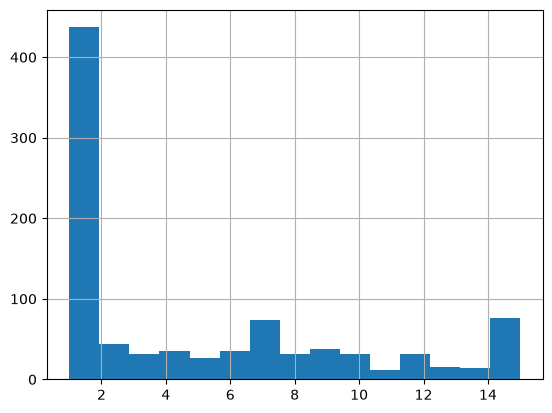

In [10]:
candidates.groupby("auction_key").size().hist(bins=15)